In [1]:
!pip install pandas numpy matplotlib scikit-learn

# 168-Hour Extrapolation and Anomaly Detection

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# 1. Load Data
df = pd.read_csv('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_01.csv')

# Filter to Run_ID 2 since it has the ~16.7 hours of data and drop NaNs
df_run2 = df[df['Run_ID'] == 2].copy()
df_run2 = df_run2.dropna(subset=['Aging_Hours', 'RDS_on_Ohm']).sort_values('Aging_Hours')

print(f"Loaded {len(df_run2)} valid data points for Run 2.")
print(f"Max observed hour: {df_run2['Aging_Hours'].max():.2f}h")


Loaded 1476 valid data points for Run 2.
Max observed hour: 16.73h


In [3]:
# 2. Fit Time-Series Curve (Training on 0 to 16.7h)
X_train = df_run2[['Aging_Hours']]
y_train = df_run2['RDS_on_Ohm']
baseline_rds = df_run2['Baseline_RDS_Ohm'].iloc[0]

model_linear = LinearRegression()
model_linear.fit(X_train, y_train)

model_poly = make_pipeline(PolynomialFeatures(2), LinearRegression())
model_poly.fit(X_train, y_train)

print("Models trained successfully on available hours.")


Models trained successfully on available hours.


In [4]:
# 3. Forecast 168 Hours
X_future = pd.DataFrame({'Aging_Hours': [168.0]})

pred_168h_linear = model_linear.predict(X_future)[0]
pred_168h_poly = model_poly.predict(X_future)[0]

deg_pct_linear = ((pred_168h_linear - baseline_rds) / baseline_rds) * 100
deg_pct_poly = ((pred_168h_poly - baseline_rds) / baseline_rds) * 100

print("--- 168-HOUR FORECAST ---")
print(f"Baseline RDS_on: {baseline_rds:.4f} Ohm")
print(f"Predicted RDS_on at 168h (Linear): {pred_168h_linear:.4f} Ohm  ({deg_pct_linear:+.2f}%)")
print(f"Predicted RDS_on at 168h (Poly):   {pred_168h_poly:.4f} Ohm  ({deg_pct_poly:+.2f}%)")


--- 168-HOUR FORECAST ---
Baseline RDS_on: 0.8261 Ohm
Predicted RDS_on at 168h (Linear): 1006.3397 Ohm  (+121724.26%)
Predicted RDS_on at 168h (Poly):   273698.1946 Ohm  (+33132927.31%)


In [5]:
# 4. Anomaly Flagging (Module A & B Logic)
safety_threshold_pct = 5.0
print("--- ANOMALY / BURN-IN SCREENING REPORT ---")
if deg_pct_linear > safety_threshold_pct:
    print(f"STATUS: FLAGGED (REJECT) - Projected degradation of {deg_pct_linear:.2f}% exceeds {safety_threshold_pct}% threshold.")
else:
    print(f"STATUS: PASS - Projected degradation of {deg_pct_linear:.2f}% is within safe limits.")


--- ANOMALY / BURN-IN SCREENING REPORT ---
STATUS: FLAGGED (REJECT) - Projected degradation of 121724.26% exceeds 5.0% threshold.


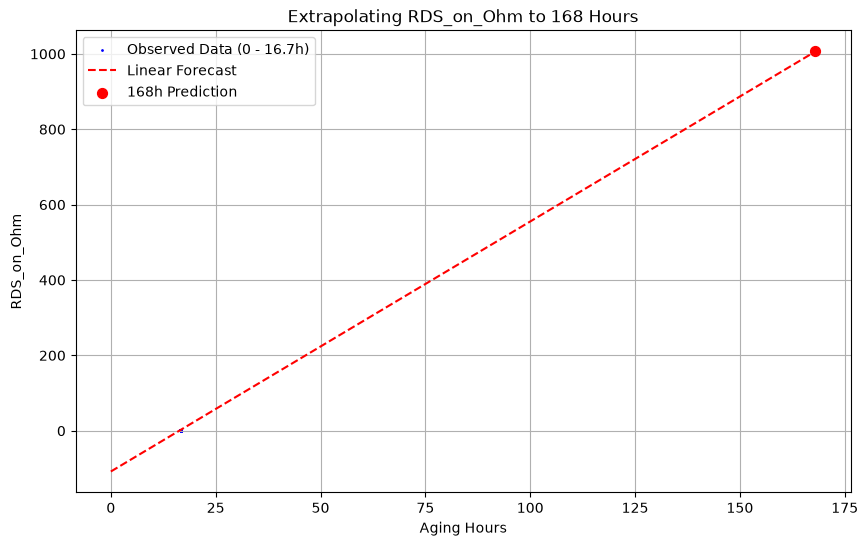

In [6]:
# 5. Visualization of the Extrapolation
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', s=1, label='Observed Data (0 - 16.7h)')
X_plot = pd.DataFrame({'Aging_Hours': np.linspace(0, 168, 500)})
plt.plot(X_plot, model_linear.predict(X_plot), color='red', linestyle='--', label='Linear Forecast')
plt.scatter([168.0], [pred_168h_linear], color='red', s=50, zorder=5, label='168h Prediction')
plt.title('Extrapolating RDS_on_Ohm to 168 Hours')
plt.xlabel('Aging Hours')
plt.ylabel('RDS_on_Ohm')
plt.legend()
plt.grid(True)
plt.show()
